# In Class Notebook, Week 09

To access this in near-real time try: https://github.com/UIUC-iSchool-DataViz/is445_bcu_fall2026/blob/master/week10/inClass_week10.ipynb

In [1]:
import pandas as pd
import numpy as np
import altair as alt
import matplotlib.pyplot as plt

In [2]:
data_url = 'https://raw.githubusercontent.com/UIUC-iSchool-DataViz/is445_data/main/building_inventory.csv'

In [3]:
buildings = pd.read_csv(data_url)

In [5]:
buildings.head(n=1)

,Agency Name,Location Name,Address,City,Zip code,County,Congress Dist,Congressional Full Name,Rep Dist,Rep Full Name,...,Bldg Status,Year Acquired,Year Constructed,Square Footage,Total Floors,Floors Above Grade,Floors Below Grade,Usage Description,Usage Description 2,Usage Description 3
0,Department of Natural Resources,Anderson Lake Conservation Area - Fulton County,Anderson Lake C.a.,Astoria,61501,Fulton,17,Cheri Bustos,93,Hammond Norine K.,...,In Use,1975,1975,144,1,1,0,Unusual,Unusual,Not provided


In [6]:
buildings.loc[buildings['Year Acquired']==0, 'Year Acquired'] = np.nan
buildings.loc[buildings['Square Footage']==0, 'Square Footage'] = np.nan

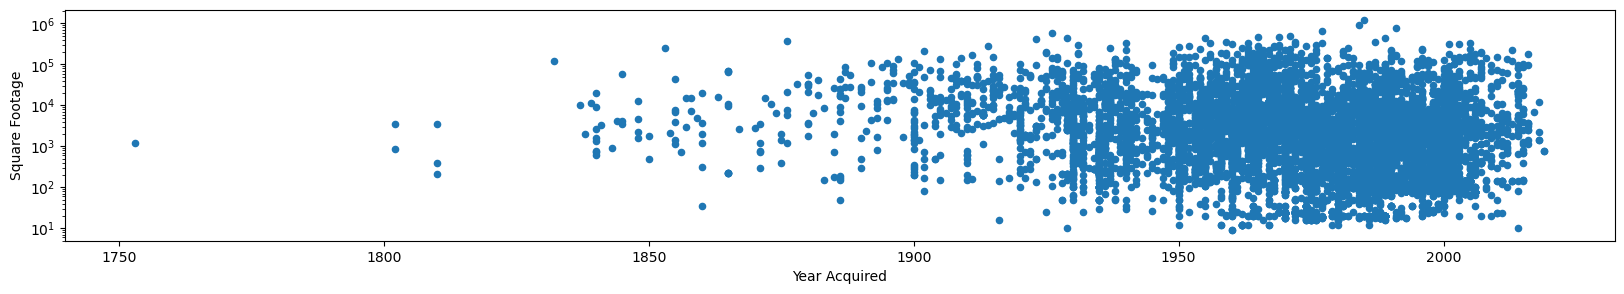

In [10]:
buildings.plot(x='Year Acquired', y='Square Footage', figsize=(20,3), kind='scatter', logy=True)
plt.show()

In [12]:
stats = buildings.groupby('Year Acquired')['Square Footage'].describe()
# stats

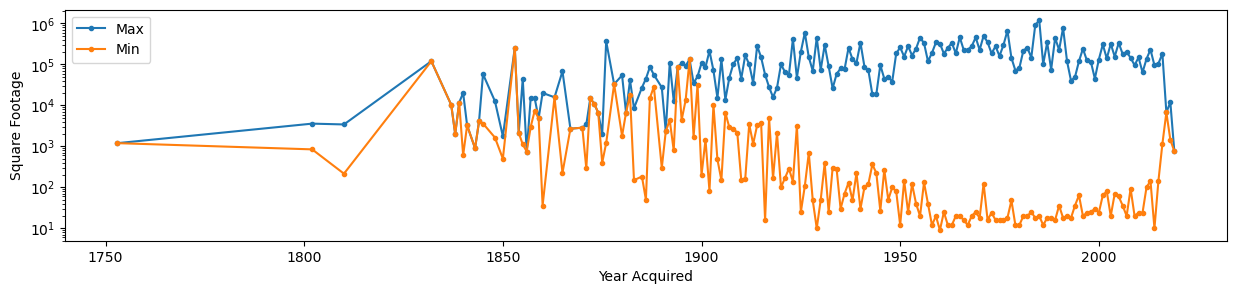

In [16]:
fig, ax = plt.subplots(figsize=(15,3))
ax.plot(stats['max'], marker='.', label = 'Max')
ax.plot(stats['min'], marker='.', label = 'Min')
ax.set_yscale('log')
ax.legend()
ax.set_xlabel('Year Acquired')
ax.set_ylabel('Square Footage')
plt.show()

## Remake this plot with Altair, first the hard way

In [20]:
stats.reset_index()

,Year Acquired,count,mean,std,min,25%,50%,75%,max
0,1753.0,1.0,1200.000000,NaN,1200.0,1200.0,1200.0,1200.00,1200.0
1,1802.0,2.0,2220.000000,1943.129435,846.0,1533.0,2220.0,2907.00,3594.0
2,1810.0,3.0,1344.333333,1809.945948,216.0,300.5,385.0,1908.50,3432.0
3,1832.0,1.0,120000.000000,NaN,120000.0,120000.0,120000.0,120000.00,120000.0
4,1837.0,1.0,10302.000000,NaN,10302.0,10302.0,10302.0,10302.00,10302.0
...,...,...,...,...,...,...,...,...,...
166,2015.0,20.0,15254.650000,29153.085290,144.0,696.0,3152.0,10590.25,105000.0
167,2016.0,10.0,30483.900000,61864.180491,1152.0,2464.0,3352.5,3793.00,184000.0
168,2017.0,1.0,6720.000000,NaN,6720.0,6720.0,6720.0,6720.00,6720.0
169,2018.0,4.0,4290.000000,5153.644342,1455.0,1455.0,1852.5,4687.50,12000.0


In [23]:
lines = alt.Chart(stats.reset_index()).mark_line().encode(
    alt.X('Year Acquired:O'), # technically should be T for reformatted into temporal
    alt.Y('max:Q')
)
lines

alt.Chart(...)

In [24]:
lines = alt.Chart(stats.reset_index()).mark_line().encode(
    alt.X('Year Acquired:Q'), # technically should be T for reformatted into temporal
    alt.Y('max:Q')
)
lines

alt.Chart(...)

In [25]:
lines = alt.Chart(stats.reset_index()).mark_line().encode(
    alt.X('Year Acquired:O'), # technically should be T for reformatted into temporal
    alt.Y('max:Q')
).properties(
    width=800
)
lines

alt.Chart(...)

In [26]:
lines = alt.Chart(stats.reset_index()).mark_line().encode(
    alt.X('Year Acquired:T'), # technically should be T for reformatted into temporal
    alt.Y('max:Q')
).properties(
    width=800
)
lines

alt.Chart(...)

In [27]:
stats.index = pd.to_datetime(stats.index.astype('int'), format='%Y')

In [29]:
#stats.index

In [32]:
lines = alt.Chart(stats.reset_index()).mark_line().encode(
    alt.X('Year Acquired:T'), # technically should be T for reformatted into temporal
    alt.Y('max:Q')
).properties(
    width=600,
    height=200
)
lines

alt.Chart(...)

In [35]:
lines = alt.Chart(stats.reset_index()).mark_line().encode(
    alt.X('Year Acquired:T'), # technically should be T for reformatted into temporal
    #alt.Y('max:Q')
).properties(
    width=600,
    height=200
)
# add layers of min & max of lines
lines = alt.layer(
    lines.mark_line(color='blue').encode(y='max:Q'), 
    lines.mark_line(color='orange').encode(y='min:Q')
)
lines

alt.LayerChart(...)

In [39]:
lines = alt.Chart(stats.reset_index()).mark_line().encode(
    alt.X('Year Acquired:T'), # can use T because have reformated index
).properties(
    width=600,
    height=100
)
# add layers of min & max of lines
lines = alt.layer(
    lines.mark_line(color='blue').encode(
        #y='max:Q'
        alt.Y('max:Q', scale=alt.Scale(type='log'))
    ), 
    lines.mark_line(color='orange').encode(
        #y='min:Q'
        alt.Y('min:Q', scale=alt.Scale(type='log'))
    )
)
lines

alt.LayerChart(...)

## Remaking the plot with Altair, the easier way -- changing the shape of the dataframe

In [40]:
stats_mini = stats[['min', 'max']]

In [41]:
stats_mini.head(n=3)

,min,max
Year Acquired,,
1753-01-01,1200.0,1200.0
1802-01-01,846.0,3594.0
1810-01-01,216.0,3432.0


In [45]:
stats_melt = stats_mini.reset_index().melt('Year Acquired', # "unpivoting" around Year Acquired
                                   var_name = 'Statistic', # new column, min/max
                                   value_name = 'Stat Value') # value of either min or max

stats_melt

,Year Acquired,Statistic,Stat Value
0,1753-01-01,min,1200.0
1,1802-01-01,min,846.0
2,1810-01-01,min,216.0
3,1832-01-01,min,120000.0
4,1837-01-01,min,10302.0
...,...,...,...
337,2015-01-01,max,105000.0
338,2016-01-01,max,184000.0
339,2017-01-01,max,6720.0
340,2018-01-01,max,12000.0


In [47]:
lines = alt.Chart(stats_melt).mark_line().encode(
    alt.X('Year Acquired:T'),
    alt.Y('Stat Value:Q', scale=alt.Scale(type='log')),
    color='Statistic:N' # color by min or max flag
).properties(
    height=100,
    width=600
)
lines

alt.Chart(...)

### Full stats, unpivoted in the plot

In [48]:
stats.head()

,count,mean,std,min,25%,50%,75%,max
Year Acquired,,,,,,,,
1753-01-01,1.0,1200.000000,NaN,1200.0,1200.0,1200.0,1200.0,1200.0
1802-01-01,2.0,2220.000000,1943.129435,846.0,1533.0,2220.0,2907.0,3594.0
1810-01-01,3.0,1344.333333,1809.945948,216.0,300.5,385.0,1908.5,3432.0
1832-01-01,1.0,120000.000000,NaN,120000.0,120000.0,120000.0,120000.0,120000.0
1837-01-01,1.0,10302.000000,NaN,10302.0,10302.0,10302.0,10302.0,10302.0


In [49]:
stats_melt2 = stats.reset_index().melt('Year Acquired',
                                       var_name='Statistic',
                                       value_name='Stats Value')
stats_melt2

,Year Acquired,Statistic,Stats Value
0,1753-01-01,count,1.0
1,1802-01-01,count,2.0
2,1810-01-01,count,3.0
3,1832-01-01,count,1.0
4,1837-01-01,count,1.0
...,...,...,...
1363,2015-01-01,max,105000.0
1364,2016-01-01,max,184000.0
1365,2017-01-01,max,6720.0
1366,2018-01-01,max,12000.0


In [53]:
lines2 = alt.Chart(stats_melt2).mark_line().encode(
    alt.X('Year Acquired:T'),
    alt.Y('Stats Value:Q', scale=alt.Scale(type='symlog')),
    color='Statistic:N' # color by min or max flag
).properties(
    height=100,
    width=600
)
lines2

alt.Chart(...)